# 04 - Lien clustering / classification

In [1]:
import logging
import os
import warnings

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from xgboost import XGBClassifier

logging.getLogger("mlflow").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", module="mlflow")
sns.set_theme(style="whitegrid")

## Configuration et données

In [2]:
DATA_PATH = "data/processed/clean_eng.csv"
FIG_DIR = "reports/figures"
SEED = 42
MLFLOW_URI = "sqlite:///mlflow.db"
EXPERIMENT = "churn-prediction"
SCORING = ["accuracy", "precision", "recall", "f1", "roc_auc"]
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

NUMERIC = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
ENGINEERED = ["charges_per_tenure", "is_new_customer", "is_month_to_month", "is_fiber", "is_electronic_check", "nb_services"]
ORDINAL = {
    "Contract": ["Month-to-month", "One year", "Two year"],
    "MultipleLines": ["No phone service", "No", "Yes"],
    "InternetService": ["No", "DSL", "Fiber optic"],
}
NOMINAL = [
    "gender", "Partner", "Dependents", "PhoneService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies", "PaperlessBilling", "PaymentMethod",
]

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT)

df = pd.read_csv(DATA_PATH)
y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns=["Churn", "customerID"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("train:", X_train.shape, "test:", X_test.shape)
print("churn train / test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

train: (5634, 26) test: (1409, 26)
churn train / test: 0.265 / 0.265


### Preprocessing

In [3]:
def build_preprocessor(use_fe=True, use_cluster=False):
    num_cols = NUMERIC + (ENGINEERED if use_fe else [])
    nom_cols = NOMINAL + (["cluster"] if use_cluster else [])
    numeric = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    ordinal = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OrdinalEncoder(categories=list(ORDINAL.values()), handle_unknown="use_encoded_value", unknown_value=-1),
    )
    nominal = make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore", drop="if_binary"))
    return ColumnTransformer(
        [("num", numeric, num_cols), ("ord", ordinal, list(ORDINAL)), ("nom", nominal, nom_cols)],
        verbose_feature_names_out=False,
    )

### Variable `cluster`

In [4]:
N_CLUSTERS = 3
CLUSTER_NUMERIC = ["SeniorCitizen", "tenure", "MonthlyCharges"] + ENGINEERED
CLUSTER_CATEGORICAL = list(ORDINAL) + NOMINAL + ["tenure_band"]


def build_cluster_pipeline(k=N_CLUSTERS):
    prep = ColumnTransformer(
        [
            ("num", StandardScaler(), CLUSTER_NUMERIC),
            ("cat", make_pipeline(OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), StandardScaler()), CLUSTER_CATEGORICAL),
        ]
    )
    return make_pipeline(prep, KMeans(n_clusters=k, n_init=10, random_state=SEED))


class ClusterFeature(BaseEstimator, TransformerMixin):
    def __init__(self, k=N_CLUSTERS):
        self.k = k

    def fit(self, X, y=None):
        self.model_ = build_cluster_pipeline(self.k).fit(X)
        return self

    def transform(self, X):
        out = X.copy()
        out["cluster"] = self.model_.predict(X)
        return out

### Pipeline et suivi MLflow

In [5]:
def make_model(clf, use_fe=True, use_cluster=False, sampler=None):
    steps = [("cluster", ClusterFeature())] if use_cluster else []
    steps.append(("prep", build_preprocessor(use_fe, use_cluster)))
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("clf", clone(clf)))
    return Pipeline(steps)


def test_metrics(model, threshold=0.5):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "test_accuracy": accuracy_score(y_test, pred),
        "test_precision": precision_score(y_test, pred),
        "test_recall": recall_score(y_test, pred),
        "test_f1": f1_score(y_test, pred),
        "test_roc_auc": roc_auc_score(y_test, proba),
    }


def run_experiment(name, clf, use_fe=True, use_cluster=False, sampler=None, threshold=0.5, tags=None):
    model = make_model(clf, use_fe, use_cluster, sampler)
    cv = cross_validate(model, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    metrics = {f"cv_{s}": cv[f"test_{s}"].mean() for s in SCORING}
    metrics["cv_roc_auc_std"] = cv["test_roc_auc"].std()
    model.fit(X_train, y_train)
    metrics.update(test_metrics(model, threshold))

    with mlflow.start_run(run_name=name):
        mlflow.set_tags({"model": type(clf).__name__, **(tags or {})})
        mlflow.log_params(
            {
                "use_feature_engineering": use_fe,
                "use_cluster": use_cluster,
                "sampler": type(sampler).__name__ if sampler is not None else "none",
                "scaler": "StandardScaler",
                "encoding": "OneHot(nominal) + Ordinal(Contract, MultipleLines, InternetService)",
                "imputation": "median(num) / most_frequent(cat)",
                "split": "80/20 stratified, seed 42",
                "threshold": threshold,
            }
        )
        mlflow.log_params({f"clf__{k}": v for k, v in clf.get_params().items()})
        mlflow.log_metrics(metrics)
        pred = (model.predict_proba(X_test)[:, 1] >= threshold).astype(int)
        cm = ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Reste", "Churn"], cmap="Blues")
        mlflow.log_figure(cm.figure_, "confusion_matrix.png")
        roc = RocCurveDisplay.from_estimator(model, X_test, y_test)
        mlflow.log_figure(roc.figure_, "roc_curve.png")
        plt.close("all")
        mlflow.sklearn.log_model(model, name="model", input_example=X_test.head(3), serialization_format="cloudpickle")
    return model, metrics

## 1. Segments appris sur le train

In [6]:
segmenter = ClusterFeature().fit(X_train)
train_c = segmenter.transform(X_train)["cluster"]
test_c = segmenter.transform(X_test)["cluster"]

pd.DataFrame(
    {
        "n_train": train_c.value_counts(),
        "churn_train": y_train.groupby(train_c).mean(),
        "churn_test": y_test.groupby(test_c).mean(),
        "tenure_moy": X_train["tenure"].groupby(train_c).mean(),
        "mensualite_moy": X_train["MonthlyCharges"].groupby(train_c).mean(),
    }
).round(3)

,n_train,churn_train,churn_test,tenure_moy,mensualite_moy
cluster,,,,,
0,2239,0.485,0.480,14.146,68.453
1,2040,0.155,0.155,53.787,88.242
2,1355,0.069,0.071,30.718,24.012


## 2. Comparaison des 4 variantes

In [7]:
def models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
        "Random Forest": RandomForestClassifier(random_state=SEED),
        "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
        "XGBoost": XGBClassifier(random_state=SEED),
    }


variants = {
    "initiales": dict(use_fe=False, use_cluster=False),
    "initiales + cluster": dict(use_fe=False, use_cluster=True),
    "initiales + FE": dict(use_fe=True, use_cluster=False),
    "initiales + FE + cluster": dict(use_fe=True, use_cluster=True),
}

rows = []
for variant, flags in variants.items():
    for name, clf in models().items():
        _, m = run_experiment(f"{name} | {variant}", clf, sampler=SMOTE(random_state=SEED), tags={"stage": "cluster_fe"}, **flags)
        rows.append({"modele": name, "variante": variant, **m})
res = pd.DataFrame(rows)

In [8]:
auc = res.pivot(index="modele", columns="variante", values="cv_roc_auc")[list(variants)]
auc.round(4)

variante,initiales,initiales + cluster,initiales + FE,initiales + FE + cluster
modele,,,,
Gradient Boosting,0.8456,0.8456,0.8457,0.8459
Logistic Regression,0.8452,0.8449,0.8470,0.8466
Random Forest,0.8177,0.8190,0.8212,0.8218
XGBoost,0.8260,0.8202,0.8202,0.8209


In [9]:
f1 = res.pivot(index="modele", columns="variante", values="cv_f1")[list(variants)]
f1.round(4)

variante,initiales,initiales + cluster,initiales + FE,initiales + FE + cluster
modele,,,,
Gradient Boosting,0.6364,0.6323,0.6272,0.6282
Logistic Regression,0.6316,0.6320,0.6338,0.6333
Random Forest,0.5739,0.5881,0.5829,0.5879
XGBoost,0.5787,0.5656,0.5718,0.5691


In [10]:
print("écart-type CV du ROC-AUC (bruit entre folds) :", res["cv_roc_auc_std"].mean().round(4))
gain = pd.DataFrame(
    {
        "gain cluster (sans FE)": auc["initiales + cluster"] - auc["initiales"],
        "gain cluster (avec FE)": auc["initiales + FE + cluster"] - auc["initiales + FE"],
        "gain FE": auc["initiales + FE"] - auc["initiales"],
        "gain FE + cluster": auc["initiales + FE + cluster"] - auc["initiales"],
    }
)
gain.round(4)

écart-type CV du ROC-AUC (bruit entre folds) : 0.011


,gain cluster (sans FE),gain cluster (avec FE),gain FE,gain FE + cluster
modele,,,,
Gradient Boosting,-0.0000,0.0002,0.0000,0.0002
Logistic Regression,-0.0003,-0.0005,0.0018,0.0014
Random Forest,0.0012,0.0006,0.0035,0.0041
XGBoost,-0.0058,0.0007,-0.0058,-0.0051


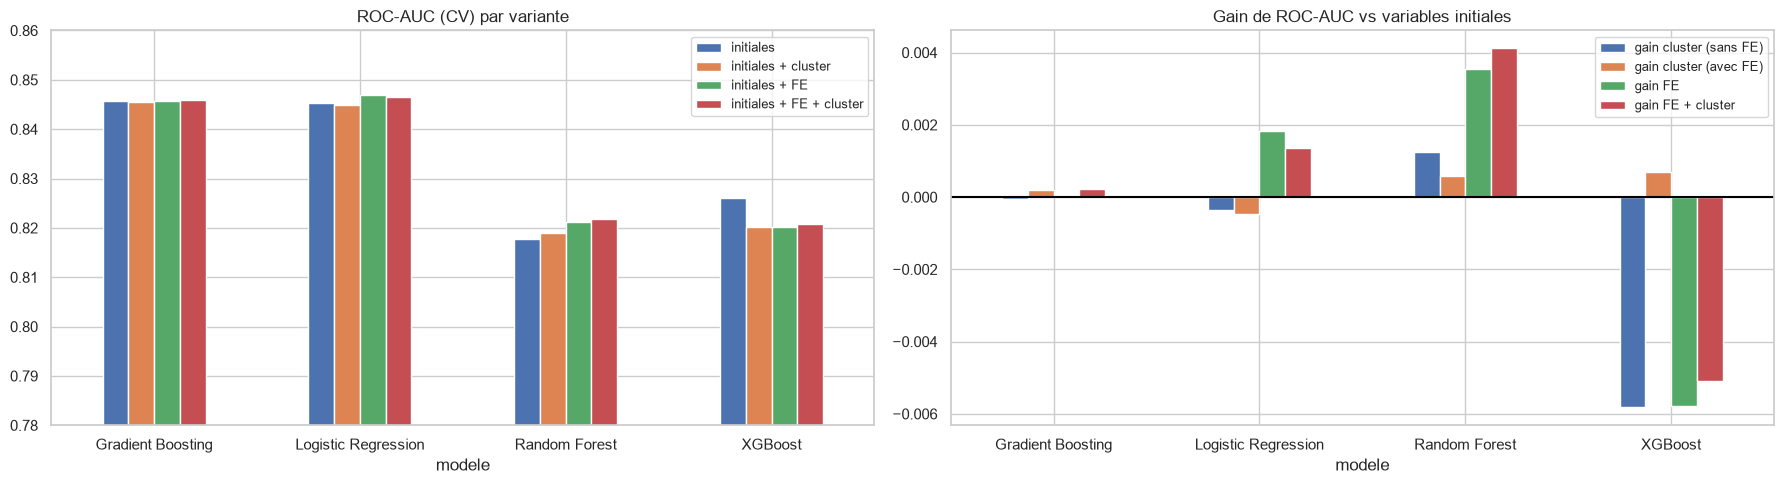

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
auc.plot.bar(ax=axes[0], ylim=(0.78, 0.86), rot=0)
axes[0].set_title("ROC-AUC (CV) par variante")
gain.plot.bar(ax=axes[1], rot=0)
axes[1].axhline(0, color="black")
axes[1].set_title("Gain de ROC-AUC vs variables initiales")
for ax in axes:
    ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/30_cluster_fe_comparison.png", dpi=110, bbox_inches="tight")
plt.show()